# Fig. 4 — Pipeline from DFT to ∂θ/∂λ with the condition required at each step (paper `draft/main_draft.tex`, `fig:workflow`)

Schematic, no data. Run all; writes `paper/figures/fig4.pdf` (+ `.png`). One column per stage of the calculation
(`analysis/pipeline/` steps 1–7): what is done (box), the condition it must satisfy for the finite difference to
measure a derivative (green), and what violating it did in this project, with the measured size (red). Every number
is quoted in the paper text (Sec. "Conditions for a valid finite difference", App. "Corrections to the DFT code", the
MnBi₂Te₄ k-list paragraph) with its source; the bugs are in `notes/bugs/` (#7 Ir moments, #19 −k stars, #23
augmentation, #21 Wannier centers as image basis; window edge: log 10-08 §12.8; `_r.dat`: log 09-10).


In [1]:
# ---- settings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = Path("/Users/treycole/Repos/axion-phonon")
# One column per stage: (title, what is done, condition, what violating it did, with the measured size). Every number
# is in the paper text (Sec. "Conditions for a valid finite difference", App. "Corrections to the DFT code",
# Sec. MBT tube) or in notes/bugs/.
STAGES = [
    ("DFT", "pw.x, four corrections;\nSCF + NSCF per\nstructure; conv_thr $10^{-10}$",
     "magnetic symmetry\nexact",
     "unpatched code: Ir\nmoments unequal by 2.5%;\n$-\\mathbf{k}$ stars dropped ($T_2^-$)"),
    ("Wannier,\nundistorted", "projected WFs, no\nminimization; window\nedges in mesh holes",
     "same bands below\neach edge in both\nstructures",
     "edge 0.16 meV from a\n$k$ star: violation\n0.7% $\\to$ 4%"),
    ("Wannier,\ndisplaced", "undistorted WFs as\nfixed trial orbitals;\nPAW overlaps with\naugmentation",
     "one gauge:\n$\\mathcal{A}_\\lambda = 0$",
     "no augmentation:\n$\\partial\\theta/\\partial Q$ moves\nup to 0.55%"),
    ("$H(\\mathbf{R})$, $X(\\mathbf{R})$", "both from the\ncheckpoint; $X$ by\nTEFD; no hopping cut",
     "full precision; link\nphases set after\nimage assignment",
     "seedname_r.dat:\n$>10^5\\times$ off on a\nsymmetry zero"),
    ("images, $\\tau$", "undistorted structure's\nWigner-Seitz images;\n$\\tau$ = its atoms",
     "same interpolant and\n$\\tau$ for both, covariant\nunder the group",
     "Wannier centers as\nbasis: $C_3$ broken\nby 62 meV"),
    ("$\\int c_2\\,d^3k$", "internal + cross +\nexternal; both\nendpoint estimates",
     "$k$ list resolves the\nsmall-gap region",
     "uniform $16^3$: 3.2\ninstead of 6.4 rad/Å\n(MnBi$_2$Te$_4$)"),
]
BOX_COLOR = "#eef2f6"
EDGE_COLOR = "#2b6cb0"
CONDITION_COLOR = "#1a6e3a"
FAILURE_COLOR = "#c0392b"
FIGSIZE = (7.0, 2.5)
FONT_SIZE = 6.5
SAVE_FIG = ROOT / "paper/figures/fig4.pdf"   # (+ .png); or None
# ---------------


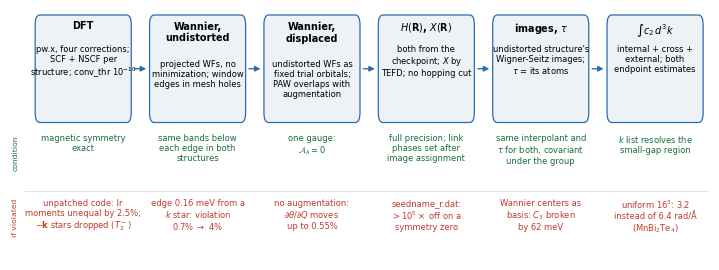

In [2]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "mathtext.fontset": "dejavusans"})
fig = plt.figure(figsize=FIGSIZE)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(-0.12, len(STAGES)); ax.set_ylim(0, 1); ax.axis("off")
w, gap = 0.84, 0.16
for i, (title, body, cond, fail) in enumerate(STAGES):
    x0 = i + gap / 2 + 0.02
    ax.add_patch(FancyBboxPatch((x0, 0.55), w, 0.43, boxstyle="round,pad=0.0,rounding_size=0.04", fc=BOX_COLOR,
                                ec=EDGE_COLOR, lw=0.9))
    ax.text(x0 + w / 2, 0.955, title, ha="center", va="top", fontsize=FONT_SIZE + 0.5, fontweight="bold")
    ax.text(x0 + w / 2, 0.80 if "\n" in title else 0.86, body, ha="center", va="top", fontsize=FONT_SIZE - 0.5,
            linespacing=1.15)
    if i < len(STAGES) - 1:
        ax.add_patch(FancyArrowPatch((x0 + w + 0.005, 0.765), (x0 + w + gap - 0.005, 0.765), arrowstyle="-|>",
                                     mutation_scale=8, lw=1.0, color=EDGE_COLOR))
    ax.text(x0 + w / 2, 0.505, cond, ha="center", va="top", fontsize=FONT_SIZE - 0.5, color=CONDITION_COLOR,
            linespacing=1.15)
    ax.text(x0 + w / 2, 0.245, fail, ha="center", va="top", fontsize=FONT_SIZE - 0.5, color=FAILURE_COLOR,
            linespacing=1.15)
ax.text(-0.1, 0.50, "condition", rotation=90, ha="left", va="top", fontsize=FONT_SIZE - 1, color=CONDITION_COLOR)
ax.text(-0.1, 0.245, "if violated", rotation=90, ha="left", va="top", fontsize=FONT_SIZE - 1, color=FAILURE_COLOR)
ax.plot([0.0, len(STAGES) - 0.02], [0.275, 0.275], color="0.85", lw=0.5)
if SAVE_FIG:
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()
